In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 02 — Extensive Exploratory Data Analysis

**Goal.** Understand the *text* of PubMed 20k RCT well enough to make informed modelling decisions: how long are sentences, how rich is the vocabulary,
which words/n-grams characterise each rhetorical role, and which simple numeric signals separate the classes.

Structure: (A) univariate → (B) multivariate → (C) NLP-specific → (D) conclusions that feed notebooks 03–04.
All analysis uses the **training split only** (180,040 sentences) so nothing learned here leaks information from dev/test.

In [2]:
import src.data as D
from collections import Counter
from src.preprocessing import tokenize, STOPWORDS, NEGATIONS, extract_dosages
train = D.load_pubmed_rct("train")
train["tokens"] = train.text.map(tokenize)
train["n_words"] = train.tokens.map(len)
train["n_chars"] = train.text.str.len()
train["avg_word_len"] = train.n_chars / train.n_words.clip(lower=1)
train["digit_ratio"] = train.text.map(lambda s: sum(c.isdigit() for c in s) / max(len(s), 1))
train["upper_ratio"] = train.text.map(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))
train["n_commas"] = train.text.str.count(",")
train["rel_pos"] = train.sent_idx / (train.n_sents - 1).clip(lower=1)
LAB = config.CLASS_LABELS
print(train.shape)
train[["label", "n_words", "n_chars", "avg_word_len", "digit_ratio", "rel_pos"]].head()

(180040, 13)


,label,n_words,n_chars,avg_word_len,digit_ratio,rel_pos
0,OBJECTIVE,44,282,6.409091,0.010638,0.000000
1,METHODS,27,143,5.296296,0.083916,0.090909
2,METHODS,14,111,7.928571,0.000000,0.181818
3,METHODS,12,67,5.583333,0.059701,0.272727
4,METHODS,30,209,6.966667,0.009569,0.363636


## A. Univariate analysis

### A1. Text length: characters, words
Sentence length determines the sequence length we must support in the BiLSTM and the transformers (a direct cost driver on CPU).

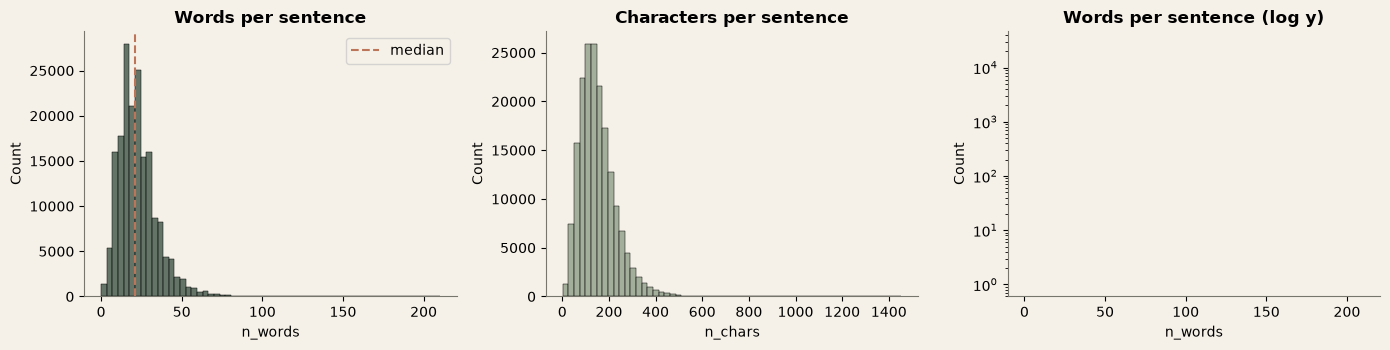

> **Observation.** The distribution is right-skewed: median 21 word tokens, 90th pct 38, 95th pct 45, 99th pct 63, maximum 210. Sequences of 64 tokens cover ≈99.1% of sentences without truncation (word tokens; word-pieces add ~30–40%). This justifies `max_seq_len = 64` as the default for CPU-bound models, which notebook 06 tests against 32.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(train.n_words, bins=60, ax=axes[0], color=PALETTE[0]); axes[0].set_title("Words per sentence"); axes[0].axvline(train.n_words.median(), color=PALETTE[1], ls="--", label="median"); axes[0].legend()
sns.histplot(train.n_chars, bins=60, ax=axes[1], color=PALETTE[3]); axes[1].set_title("Characters per sentence")
sns.histplot(train.n_words, bins=60, ax=axes[2], color=PALETTE[2], log_scale=(False, True)); axes[2].set_title("Words per sentence (log y)")
plt.tight_layout(); plt.show()
q = train.n_words.quantile([.5, .9, .95, .99]).astype(int)
note(f"The distribution is right-skewed: median {q[.5]} word tokens, 90th pct {q[.9]}, 95th pct {q[.95]}, 99th pct {q[.99]}, maximum {train.n_words.max()}. "
     f"Sequences of 64 tokens cover ≈{(train.n_words <= 64).mean():.1%} of sentences without truncation (word tokens; word-pieces add ~30–40%). "
     f"This justifies `max_seq_len = 64` as the default for CPU-bound models, which notebook 06 tests against 32.")

### A2. Sentence count per abstract and abstract length in words

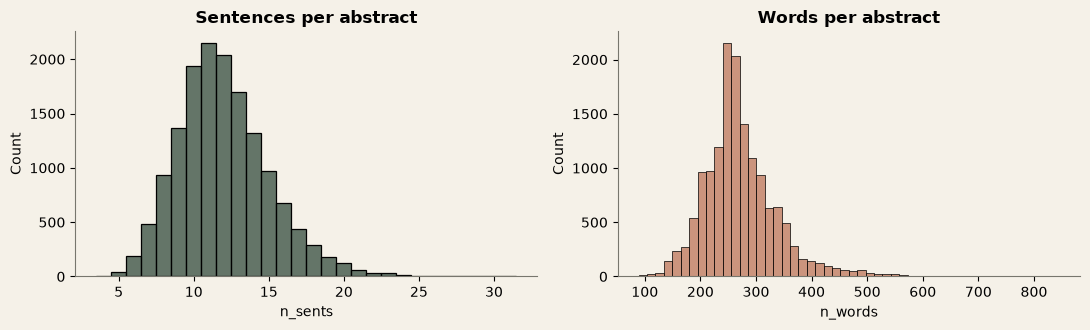

> **Observation.** Abstracts have a median of 12 sentences and 262 words (max 845). 5.9% of abstracts exceed ~380 words — relevant for the summarizer's window, but not for sentence-level classification.

In [4]:
ab = train.groupby("abstract_id").agg(n_sents=("n_sents", "first"), n_words=("n_words", "sum"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(ab.n_sents, discrete=True, ax=axes[0], color=PALETTE[0]); axes[0].set_title("Sentences per abstract")
sns.histplot(ab.n_words, bins=50, ax=axes[1], color=PALETTE[1]); axes[1].set_title("Words per abstract")
plt.tight_layout(); plt.show()
note(f"Abstracts have a median of {ab.n_sents.median():.0f} sentences and {ab.n_words.median():.0f} words (max {ab.n_words.max()}). "
     f"{(ab.n_words > 380).mean():.1%} of abstracts exceed ~380 words — relevant for the summarizer's window, but not for sentence-level classification.")

### A3. Class distribution

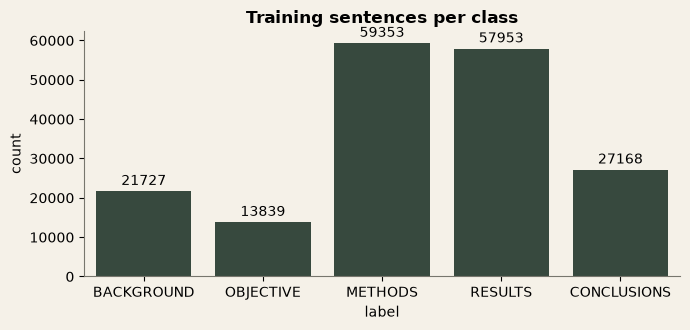

> **Observation.** METHODS (33.0%) and RESULTS (32.2%) dominate; OBJECTIVE is the minority (7.7%). A classifier that always predicted METHODS would already score 33.0% accuracy — a baseline every model must beat, and the reason macro-F1 is the primary metric.

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
sns.countplot(data=train, x="label", order=LAB, ax=ax, color=PALETTE[0]); ax.set_title("Training sentences per class")
for c in ax.containers: ax.bar_label(c, fmt="%d", padding=2)
plt.tight_layout(); plt.show()
sh = train.label.value_counts(normalize=True)
note(f"METHODS ({sh['METHODS']:.1%}) and RESULTS ({sh['RESULTS']:.1%}) dominate; OBJECTIVE is the minority ({sh['OBJECTIVE']:.1%}). "
     f"A classifier that always predicted METHODS would already score {sh.max():.1%} accuracy — a baseline every model must beat, and the reason macro-F1 is the primary metric.")

### A4. Frequent and rare words

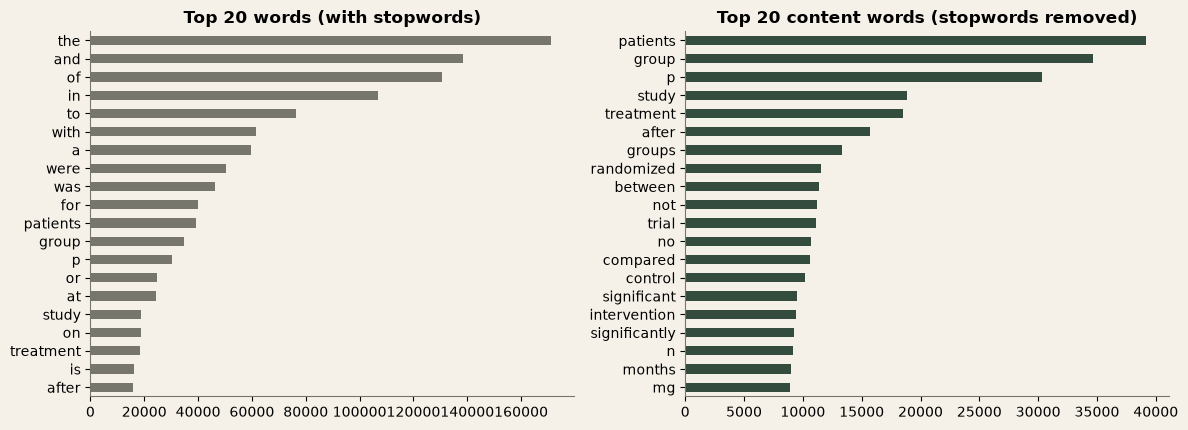

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
random hapax legomena (freq = 1),zero-first-order,42284825,intervention-concealed,13.96,47.3911.63,severity-weighted,00088699,mama,12613000864729,usanz,kidney-pancreas,maquet,maidenhead,43.54.8,0.715


> **Observation.** Total tokens: 4,080,593; vocabulary: 82,725; hapax legomena: 35,339 (42.7% of the vocabulary but only 0.87% of tokens). The rarest words are identifiers, misspellings, compound chemical/gene names and numbers — a TF-IDF `min_df=2` filter safely removes them, while subword tokenisers (BERT) can still compose them.

In [6]:
all_tokens = [t for toks in train.tokens for t in toks]
wc = Counter(all_tokens)
alpha = {w: c for w, c in wc.items() if w.isalpha()}
content = {w: c for w, c in alpha.items() if w not in STOPWORDS}
top_all = pd.Series(alpha).sort_values(ascending=False).head(20)
top_content = pd.Series(content).sort_values(ascending=False).head(20)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
top_all.sort_values().plot.barh(ax=axes[0], color=PALETTE[4]); axes[0].set_title("Top 20 words (with stopwords)")
top_content.sort_values().plot.barh(ax=axes[1], color=PALETTE[0]); axes[1].set_title("Top 20 content words (stopwords removed)")
plt.tight_layout(); plt.show()
hapax = [w for w, c in wc.items() if c == 1]
rng = np.random.default_rng(config.SEED)
display(pd.DataFrame({"random hapax legomena (freq = 1)": rng.choice(hapax, 15, replace=False)}).T)
note(f"Total tokens: {len(all_tokens):,}; vocabulary: {len(wc):,}; hapax legomena: {len(hapax):,} ({len(hapax) / len(wc):.1%} of the vocabulary but only {len(hapax) / len(all_tokens):.2%} of tokens). "
     f"The rarest words are identifiers, misspellings, compound chemical/gene names and numbers — a TF-IDF `min_df=2` filter safely removes them, while subword tokenisers (BERT) can still compose them.")

## B. Multivariate analysis

### B1. Text length by category

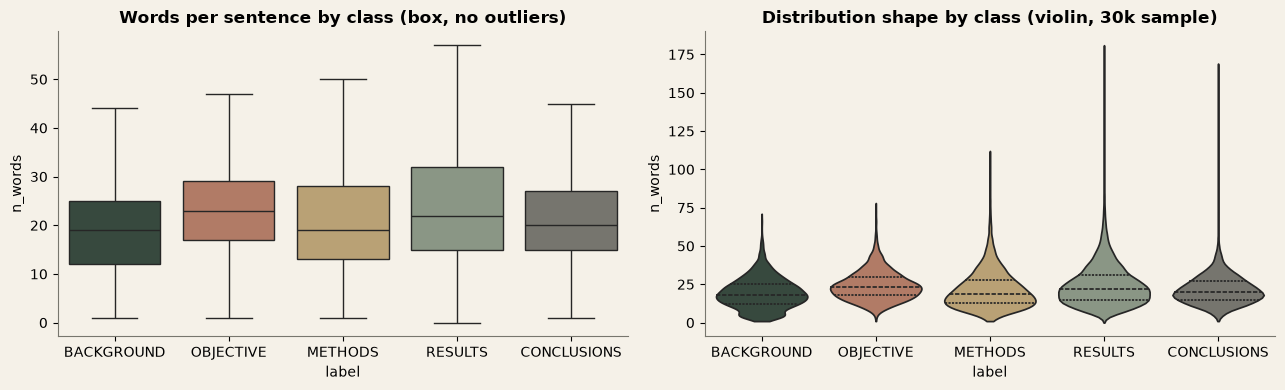

> **Observation.** Kruskal–Wallis H = 4151, p = 0, ε² = 0.023 (effect size small). Median length is OBJECTIVE = 23 words vs BACKGROUND = 19. Length differs significantly between classes but overlaps heavily, so length alone is a weak feature; it may complement lexical features.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="label", y="n_words", order=LAB, ax=axes[0], palette=PALETTE[:5], showfliers=False); axes[0].set_title("Words per sentence by class (box, no outliers)")
sns.violinplot(data=train.sample(30000, random_state=0), x="label", y="n_words", order=LAB, ax=axes[1], palette=PALETTE[:5], cut=0, inner="quartile"); axes[1].set_title("Distribution shape by class (violin, 30k sample)")
plt.tight_layout(); plt.show()
from scipy.stats import kruskal
groups = [train.loc[train.label == l, "n_words"].values for l in LAB]
H, p = kruskal(*groups); eps2 = H / (len(train) - 1)
med = train.groupby("label").n_words.median().reindex(LAB)
note(f"Kruskal–Wallis H = {H:.0f}, p = {p:.2g}, ε² = {eps2:.3f} (effect size {'small' if eps2 < .06 else 'moderate' if eps2 < .14 else 'large'}). "
     f"Median length is {med.idxmax()} = {med.max():.0f} words vs {med.idxmin()} = {med.min():.0f}. Length differs significantly between classes but overlaps heavily, "
     f"so length alone is a weak feature; it may complement lexical features.")

### B2. Numerical feature relationships

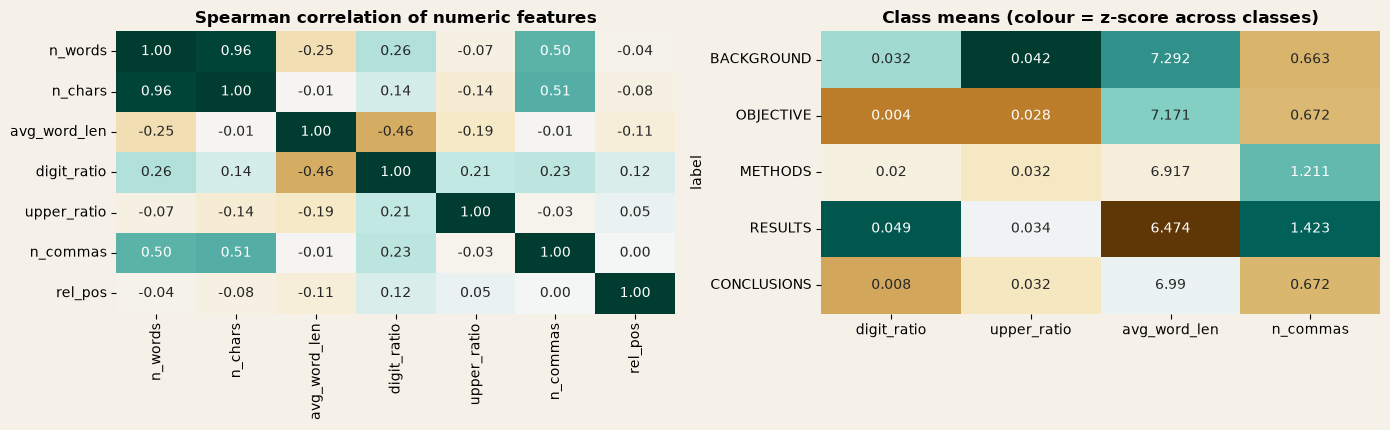

> **Observation.** As expected, `n_chars` and `n_words` are almost collinear (ρ = 0.96) so only one is needed. Digit share is highest in RESULTS (0.049) and lowest in OBJECTIVE (0.004) — numbers carry class information, which is why preprocessing must **not** strip digits blindly (notebook 03 compares strategies).

In [8]:
num_cols = ["n_words", "n_chars", "avg_word_len", "digit_ratio", "upper_ratio", "n_commas", "rel_pos"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.heatmap(train[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="BrBG", center=0, ax=axes[0], cbar=False); axes[0].set_title("Spearman correlation of numeric features")
means = train.groupby("label")[["digit_ratio", "upper_ratio", "avg_word_len", "n_commas"]].mean().reindex(LAB)
sns.heatmap((means - means.mean()) / means.std(), annot=means.round(3), fmt="", cmap="BrBG", center=0, ax=axes[1], cbar=False); axes[1].set_title("Class means (colour = z-score across classes)")
plt.tight_layout(); plt.show()
note(f"As expected, `n_chars` and `n_words` are almost collinear (ρ = {train[['n_chars','n_words']].corr(method='spearman').iloc[0,1]:.2f}) so only one is needed. "
     f"Digit share is highest in {means.digit_ratio.idxmax()} ({means.digit_ratio.max():.3f}) and lowest in {means.digit_ratio.idxmin()} ({means.digit_ratio.min():.3f}) — numbers carry class information, "
     f"which is why preprocessing must **not** strip digits blindly (notebook 03 compares strategies).")

### B3. Position inside the abstract × class

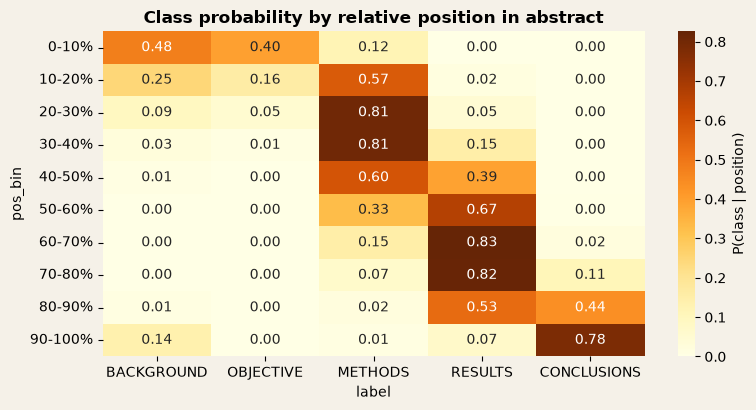

> **Observation.** Position is extremely informative: the first sentence is OBJECTIVE with probability 50.1%, the last sentence is CONCLUSIONS with probability 79.8%. A model that sees only the isolated sentence discards this signal. MediScope keeps the *sentence-only* setup for the main comparison (fair across all architectures and usable on a single pasted sentence) and reports a position-augmented ablation in notebook 04.

In [9]:
train["pos_bin"] = pd.cut(train.rel_pos, bins=np.linspace(0, 1, 11), include_lowest=True, labels=[f"{i*10}-{i*10+10}%" for i in range(10)])
ct = pd.crosstab(train.pos_bin, train.label, normalize="index").reindex(columns=LAB)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrBr", ax=ax, cbar_kws={"label": "P(class | position)"}); ax.set_title("Class probability by relative position in abstract")
plt.tight_layout(); plt.show()
first = train[train.sent_idx == 0].label.value_counts(normalize=True)
last = train[train.sent_idx == train.n_sents - 1].label.value_counts(normalize=True)
note(f"Position is extremely informative: the first sentence is {first.idxmax()} with probability {first.max():.1%}, the last sentence is {last.idxmax()} with probability {last.max():.1%}. "
     f"A model that sees only the isolated sentence discards this signal. MediScope keeps the *sentence-only* setup for the main comparison (fair across all architectures and usable on a single pasted sentence) and reports a position-augmented ablation in notebook 04.")

### B4. Vocabulary by category

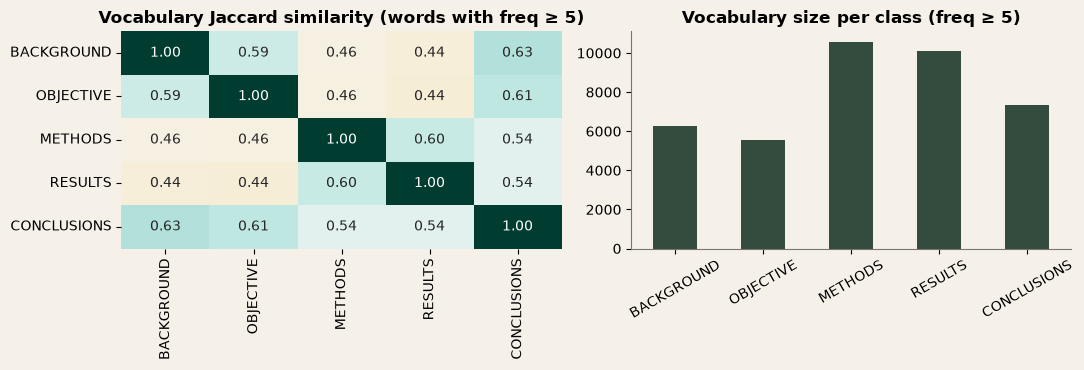

> **Observation.** Class vocabularies overlap strongly (mean off-diagonal Jaccard 0.53); the most similar pair is BACKGROUND/CONCLUSIONS (0.63), the least similar OBJECTIVE/RESULTS (0.44). The classes are therefore separated by *which* common words are used *how often* and in what combination, not by disjoint vocabularies — a good fit for weighted n-gram features.

In [10]:
vocab_by = {l: Counter(t for toks in train.loc[train.label == l, "tokens"] for t in toks if t.isalpha()) for l in LAB}
V = {l: {w for w, c in cnt.items() if c >= 5} for l, cnt in vocab_by.items()}
jac = pd.DataFrame([[len(V[a] & V[b]) / len(V[a] | V[b]) for b in LAB] for a in LAB], index=LAB, columns=LAB)
sizes = pd.Series({l: len(v) for l, v in V.items()})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="BrBG", vmin=0, vmax=1, ax=axes[0], cbar=False); axes[0].set_title("Vocabulary Jaccard similarity (words with freq ≥ 5)")
sizes.plot.bar(ax=axes[1], color=PALETTE[0]); axes[1].set_title("Vocabulary size per class (freq ≥ 5)"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
off = jac.where(~np.eye(len(LAB), dtype=bool)).stack()
note(f"Class vocabularies overlap strongly (mean off-diagonal Jaccard {off.mean():.2f}); the most similar pair is {off.idxmax()[0]}/{off.idxmax()[1]} ({off.max():.2f}), the least similar {off.idxmin()[0]}/{off.idxmin()[1]} ({off.min():.2f}). "
     f"The classes are therefore separated by *which* common words are used *how often* and in what combination, not by disjoint vocabularies — a good fit for weighted n-gram features.")

### B5. Distinctive vocabulary per class (smoothed log-odds)

For class *c* we compare word rates against all other classes using an informative-Dirichlet-prior log-odds *z*-score (Monroe et al., 2008), which avoids the
well-known bias of raw log-odds towards rare words. Only words with ≥ 50 total occurrences are shown.

In [11]:
tot = Counter(); [tot.update(c) for c in vocab_by.values()]
V_size = len(tot); a0 = 0.01 * V_size
rows = {}
for l in LAB:
    cc = vocab_by[l]; rest = {w: tot[w] - cc.get(w, 0) for w in tot}
    nc, nr = sum(cc.values()), sum(rest.values())
    scores = {}
    for w, t in tot.items():
        if t < 50: continue
        a = 0.01 * (t / sum(tot.values())) * V_size * 100 + 1e-3
        yc, yr = cc.get(w, 0), rest[w]
        d = np.log((yc + a) / (nc + a0 - yc - a)) - np.log((yr + a) / (nr + a0 - yr - a))
        var = 1 / (yc + a) + 1 / (yr + a)
        scores[w] = d / np.sqrt(var)
    rows[l] = [w for w, _ in sorted(scores.items(), key=lambda kv: -kv[1])[:12]]
display(pd.DataFrame(rows, index=range(1, 13)))
note("Top-5 distinctive words per class — " + "; ".join(f"**{l}**: {', '.join(rows[l][:5])}" for l in LAB) + ". "
     "Read these against the rhetorical roles: a good result is that each list is semantically coherent with its role (aims, procedures, statistics, interpretation). "
     "Words that look like noise (identifiers, rare tokens) would indicate the need for stricter frequency thresholds.")

,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
1,is,to,were,p,be
2,been,evaluate,randomized,group,may
3,has,of,or,significantly,that
4,are,compare,n,significant,is
5,nct,determine,randomly,in,effective
6,have,whether,mg,vs,can
7,gov,efficacy,received,was,results
8,clinicaltrials,investigate,trial,no,not
9,this,aim,primary,groups,findings
10,trials,assess,using,mean,further


> **Observation.** Top-5 distinctive words per class — **BACKGROUND**: is, been, has, are, nct; **OBJECTIVE**: to, evaluate, of, compare, determine; **METHODS**: were, randomized, or, n, randomly; **RESULTS**: p, group, significantly, significant, in; **CONCLUSIONS**: be, may, that, is, effective. Read these against the rhetorical roles: a good result is that each list is semantically coherent with its role (aims, procedures, statistics, interpretation). Words that look like noise (identifiers, rare tokens) would indicate the need for stricter frequency thresholds.

## C. NLP-specific analysis

### C1. Zipf's law and vocabulary growth (Heaps' law)

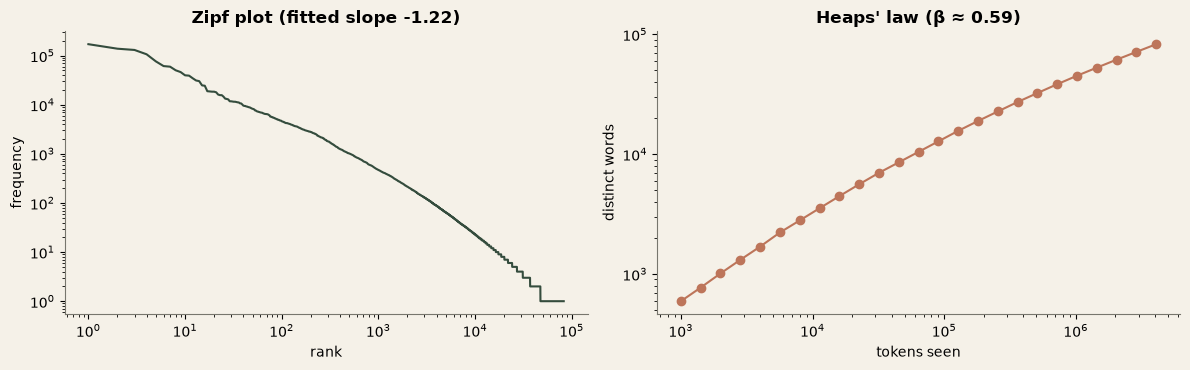

> **Observation.** The rank–frequency curve is close to a power law (slope -1.22, Zipf ideal ≈ −1). Vocabulary still grows sub-linearly with exponent β ≈ 0.59 and has not saturated at 4,080,593 tokens, so out-of-vocabulary words *will* appear at test time — a practical argument for subword models and for `<unk>` handling in the BiLSTM.

In [12]:
freq = np.array(sorted(wc.values(), reverse=True)); rank = np.arange(1, len(freq) + 1)
sel = (rank >= 10) & (rank <= 10_000)
slope, intercept = np.polyfit(np.log10(rank[sel]), np.log10(freq[sel]), 1)
rng = np.random.default_rng(config.SEED); shuffled = rng.permutation(np.array(all_tokens, dtype=object))
ns = np.unique(np.logspace(3, np.log10(len(shuffled)), 25).astype(int))
seen, growth, last = set(), [], 0
for n in ns:
    seen.update(shuffled[last:n]); last = n; growth.append(len(seen))
hb, ha = np.polyfit(np.log10(ns), np.log10(growth), 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].loglog(rank, freq, color=PALETTE[0]); axes[0].set_xlabel("rank"); axes[0].set_ylabel("frequency"); axes[0].set_title(f"Zipf plot (fitted slope {slope:.2f})")
axes[1].loglog(ns, growth, "o-", color=PALETTE[1]); axes[1].set_xlabel("tokens seen"); axes[1].set_ylabel("distinct words"); axes[1].set_title(f"Heaps' law (β ≈ {hb:.2f})")
plt.tight_layout(); plt.show()
note(f"The rank–frequency curve is close to a power law (slope {slope:.2f}, Zipf ideal ≈ −1). Vocabulary still grows sub-linearly with exponent β ≈ {hb:.2f} and has not saturated at {len(shuffled):,} tokens, "
     f"so out-of-vocabulary words *will* appear at test time — a practical argument for subword models and for `<unk>` handling in the BiLSTM.")

### C2. Unigrams, bigrams, trigrams

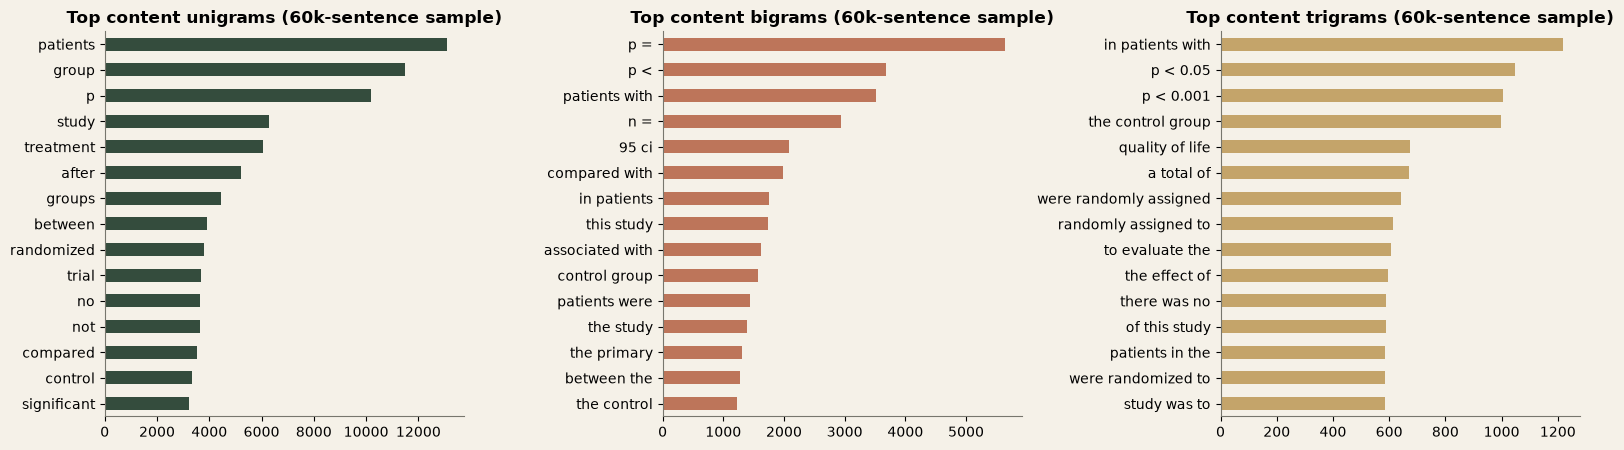

> **Observation.** Most frequent content trigrams: in patients with, p < 0.05, p < 0.001, the control group; bigrams: p =, p <, patients with, n =. Multi-word units such as these are standard trial phrasing and cannot be represented by unigrams alone, which motivates n-gram TF-IDF features (tested formally in notebook 03).

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
samp = train.sample(60000, random_state=config.SEED)
def top_ngrams(texts, n, k=15):
    cv = CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, ngram_range=(n, n), min_df=5, stop_words=None)
    X = cv.fit_transform(texts); counts = np.asarray(X.sum(0)).ravel(); vocab = np.array(cv.get_feature_names_out())
    keep = [i for i in np.argsort(-counts) if not all(t in STOPWORDS or not t.isalpha() for t in vocab[i].split())][:k]
    return pd.Series(counts[keep], index=vocab[keep])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6)); NG = {}
for ax, (n, nm, col) in zip(axes, [(1, "Unigrams", PALETTE[0]), (2, "Bigrams", PALETTE[1]), (3, "Trigrams", PALETTE[2])]):
    NG[n] = top_ngrams(samp.text, n); NG[n].sort_values().plot.barh(ax=ax, color=col); ax.set_title(f"Top content {nm.lower()} (60k-sentence sample)")
plt.tight_layout(); plt.show()
note(f"Most frequent content trigrams: {', '.join(NG[3].index[:4])}; bigrams: {', '.join(NG[2].index[:4])}. Multi-word units such as these are standard trial phrasing and "
     "cannot be represented by unigrams alone, which motivates n-gram TF-IDF features (tested formally in notebook 03).")

### C3. Top bigrams per class

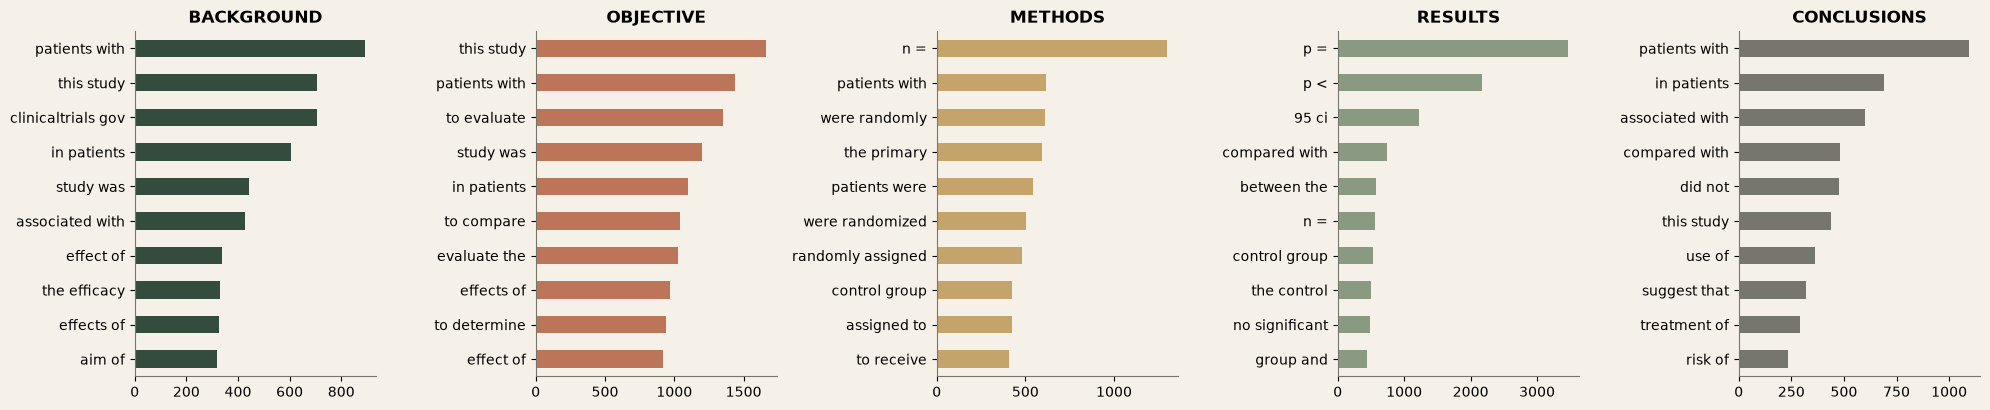

> **Observation.** Most frequent content bigram per class — **BACKGROUND**: patients with; **OBJECTIVE**: this study; **METHODS**: n =; **RESULTS**: p =; **CONCLUSIONS**: patients with. Where these differ across classes, bigrams carry role information that unigrams blur; this supports testing the (1,2)-gram TF-IDF configuration in notebook 03.

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2)); PB = {}
for ax, l, col in zip(axes, LAB, PALETTE):
    PB[l] = top_ngrams(train.loc[train.label == l, "text"].sample(min(12000, (train.label == l).sum()), random_state=1), 2, 10); PB[l].sort_values().plot.barh(ax=ax, color=col); ax.set_title(l)
plt.tight_layout(); plt.show()
note("Most frequent content bigram per class — " + "; ".join(f"**{l}**: {PB[l].index[0]}" for l in LAB) + ". "
     "Where these differ across classes, bigrams carry role information that unigrams blur; this supports testing the (1,2)-gram TF-IDF configuration in notebook 03.")

### C4. Stopword and negation analysis

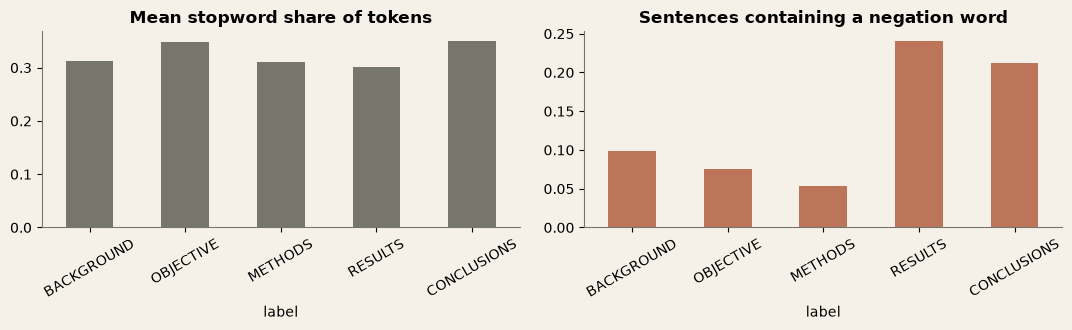

> **Observation.** Stopwords make up 31.7% of tokens on average, ranging from 30.2% (RESULTS) to 35.1% (CONCLUSIONS). Negation words appear in 14.5% of sentences overall and most often in RESULTS (24.1%). Because *no/not/without* flip clinical meaning ("no significant difference"), the project's stopword list **keeps all negations**.

In [15]:
train["sw_share"] = train.tokens.map(lambda t: np.mean([w in STOPWORDS for w in t]) if t else 0)
train["neg"] = train.tokens.map(lambda t: any(w in NEGATIONS for w in t))
st = train.groupby("label").agg(stopword_share=("sw_share", "mean"), negation_rate=("neg", "mean")).reindex(LAB)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
st.stopword_share.plot.bar(ax=axes[0], color=PALETTE[4]); axes[0].set_title("Mean stopword share of tokens"); axes[0].tick_params(axis="x", rotation=30)
st.negation_rate.plot.bar(ax=axes[1], color=PALETTE[1]); axes[1].set_title("Sentences containing a negation word"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
note(f"Stopwords make up {train.sw_share.mean():.1%} of tokens on average, ranging from {st.stopword_share.min():.1%} ({st.stopword_share.idxmin()}) to {st.stopword_share.max():.1%} ({st.stopword_share.idxmax()}). "
     f"Negation words appear in {train.neg.mean():.1%} of sentences overall and most often in {st.negation_rate.idxmax()} ({st.negation_rate.max():.1%}). "
     f"Because *no/not/without* flip clinical meaning (\"no significant difference\"), the project's stopword list **keeps all negations**.")

### C5. Word clouds (content words)

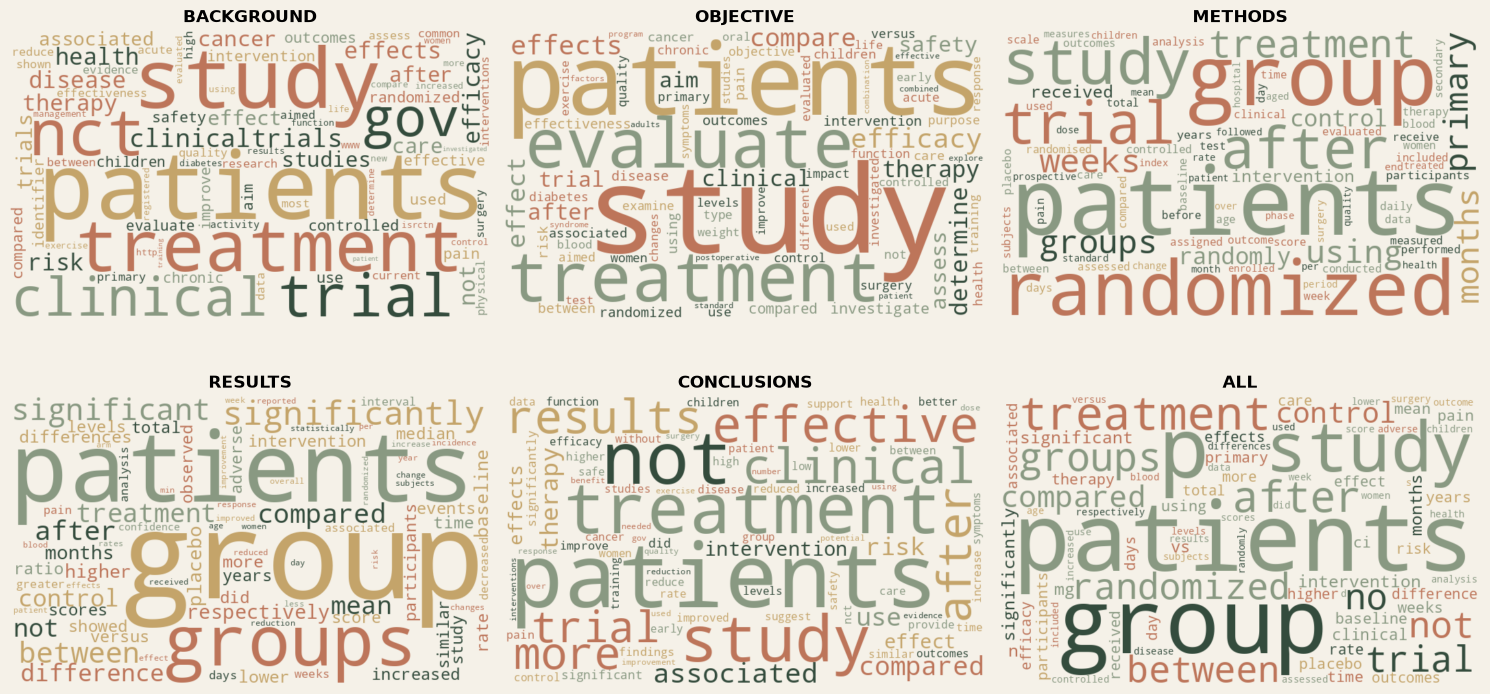

> **Observation.** Clouds are dominated by shared trial vocabulary (*patients*, *group*, *treatment*), confirming the earlier finding that classes share most words; they are descriptive only — the log-odds table in B5 is the more reliable view of what is *distinctive*.

In [16]:
from wordcloud import WordCloud
import random
def color_fn(*a, **k): return random.choice(PALETTE[:4])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, l in zip(axes.ravel(), LAB + ["ALL"]):
    freqs = {w: c for w, c in (content if l == "ALL" else {w: c for w, c in vocab_by[l].items() if w not in STOPWORDS and len(w) > 2}).items()}
    wcld = WordCloud(width=700, height=420, background_color="#F5F1E8", color_func=color_fn, max_words=80, random_state=1).generate_from_frequencies(freqs)
    ax.imshow(wcld, interpolation="bilinear"); ax.set_title(l); ax.axis("off")
plt.tight_layout(); plt.show()
note("Clouds are dominated by shared trial vocabulary (*patients*, *group*, *treatment*), confirming the earlier finding that classes share most words; "
     "they are descriptive only — the log-odds table in B5 is the more reliable view of what is *distinctive*.")

### C6. Medical terminology frequency by category

A small **illustrative** lexicon (not a clinical ontology) grouped by theme; each cell is the share of sentences of that class containing the term.

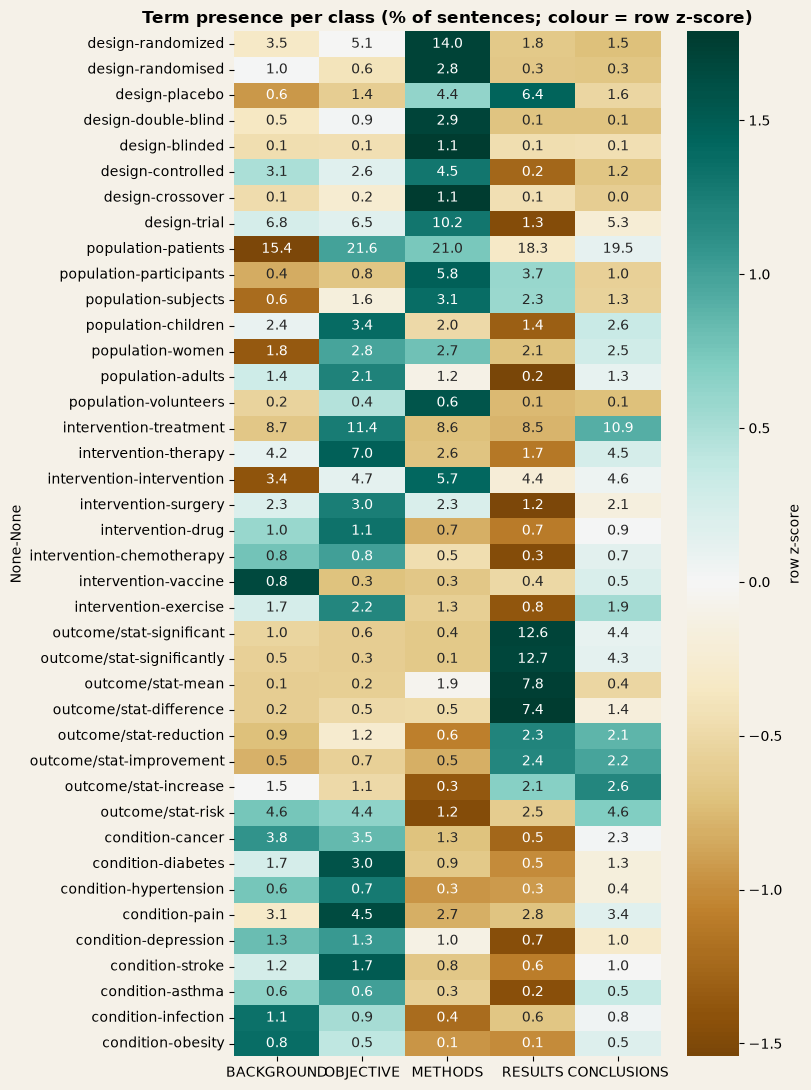

> **Observation.** Across the 40 lexicon terms the class with the highest usage is: OBJECTIVE for 16, METHODS for 11, RESULTS for 7, BACKGROUND for 5, CONCLUSIONS for 1. Averaged by theme, the dominant class is — **condition** → OBJECTIVE; **design** → METHODS; **intervention** → OBJECTIVE; **outcome/stat** → RESULTS; **population** → METHODS.

In [17]:
LEX = {
  "design": ["randomized", "randomised", "placebo", "double-blind", "blinded", "controlled", "crossover", "trial"],
  "population": ["patients", "participants", "subjects", "children", "women", "adults", "volunteers"],
  "intervention": ["treatment", "therapy", "intervention", "surgery", "drug", "chemotherapy", "vaccine", "exercise"],
  "outcome/stat": ["significant", "significantly", "mean", "difference", "reduction", "improvement", "increase", "risk"],
  "condition": ["cancer", "diabetes", "hypertension", "pain", "depression", "stroke", "asthma", "infection", "obesity"],
}
terms = [(g, t) for g, ts in LEX.items() for t in ts]
tok_sets = train.tokens.map(set)
tab = pd.DataFrame({l: [tok_sets[train.label == l].map(lambda s: t in s).mean() for g, t in terms] for l in LAB}, index=pd.MultiIndex.from_tuples(terms))
z = tab.sub(tab.mean(1), axis=0).div(tab.std(1) + 1e-9, axis=0)
fig, ax = plt.subplots(figsize=(8, 11))
sns.heatmap(z, annot=(tab * 100).round(1), fmt="", cmap="BrBG", center=0, ax=ax, cbar_kws={"label": "row z-score"}); ax.set_title("Term presence per class (% of sentences; colour = row z-score)")
plt.tight_layout(); plt.show()
best = tab.idxmax(axis=1).value_counts()
grp = tab.groupby(level=0).mean().idxmax(axis=1)
note(f"Across the {len(terms)} lexicon terms the class with the highest usage is: " + ", ".join(f"{k} for {v}" for k, v in best.items()) + ". "
     "Averaged by theme, the dominant class is — " + "; ".join(f"**{g}** → {c}" for g, c in grp.items()) + ".")

### C7. Dosages, percentages and p-values as class signals

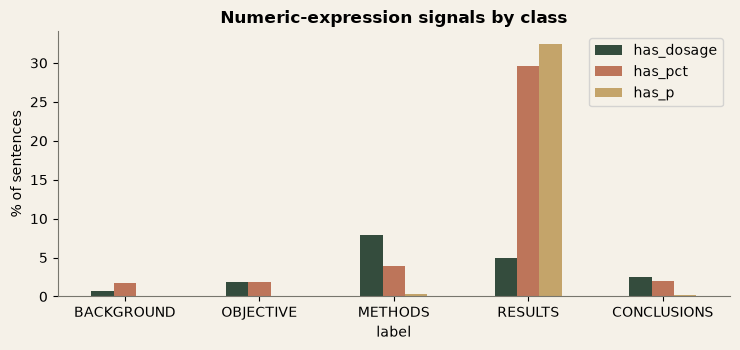

> **Observation.** p-value expressions occur in 32.4% of RESULTS sentences vs 0.0% of OBJECTIVE; dosage expressions peak in METHODS (7.9%). Numbers and units are therefore **features, not noise** — notebook 03 tests replacing them with shape tokens versus keeping them.

In [18]:
train["has_dosage"] = train.text.map(lambda s: bool(extract_dosages(s)))
train["has_pct"] = train.text.str.contains("%")
train["has_p"] = train.text.str.contains(r"\bP\s?[<=>]", case=False, regex=True)
sig = train.groupby("label")[["has_dosage", "has_pct", "has_p"]].mean().reindex(LAB) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.6)); sig.plot.bar(ax=ax, color=PALETTE[:3]); ax.set_ylabel("% of sentences"); ax.tick_params(axis="x", rotation=0); ax.set_title("Numeric-expression signals by class")
plt.tight_layout(); plt.show()
note(f"p-value expressions occur in {sig.has_p.max():.1f}% of {sig.has_p.idxmax()} sentences vs {sig.has_p.min():.1f}% of {sig.has_p.idxmin()}; dosage expressions peak in {sig.has_dosage.idxmax()} ({sig.has_dosage.max():.1f}%). "
     f"Numbers and units are therefore **features, not noise** — notebook 03 tests replacing them with shape tokens versus keeping them.")

## D. Conclusions that drive later notebooks

1. **Lengths:** `max_seq_len=64` covers most sentences; 32 will be tested as a speed/accuracy trade-off.
2. **Class imbalance:** use macro-F1; try class weights in classical models.
3. **Vocabulary:** heavy-tailed with many hapax legomena → TF-IDF with `min_df`, subwords for transformers, `<unk>` for BiLSTM.
4. **Numbers, units, negations are informative** → no blind stripping; stopword list preserves negations.
5. **Position** is a very strong signal but sentence-only models cannot use it → separate ablation (notebook 04).
6. **N-grams (1–2)** capture formulaic phrases; trigrams add little new vocabulary at large cost → test (1,2) vs (1,3) vs unigrams in notebook 03.